# Limpieza y preprocesamiento — Dow Jones (Reto 9)

**Dataset de entrada:** `Datos/DowJones/*.csv` (26 ficheros, uno por acción, formato `marketstack`).

**Objetivo de este script:** dejar un dataset único, limpio, con frecuencia homogénea y sin missings,
que sirva de entrada para la selección de la cartera (Sección 3 de la descripción técnica).

Pasos (siguiendo el procedimiento visto en clase — Procesamiento de Series Temporales):
1. Carga y unificación
2. Duplicados y orden temporal
3. Comprobación de calidad / coherencia OHLC
4. Homogenización de la frecuencia muestral
5. Tratamiento de missings
6. Completado con Yahoo Finance
7. Análisis descriptivo
8. Guardado del dataset limpio

In [2]:
import pandas as pd
import os


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

## 1. Carga y unificación de los datos

In [4]:
# Ruta relativa dentro del repositorio (ajustar si la estructura de carpetas es otra)
RUTA_DATOS = os.path.join("Datos", "DowJones")

lista_df = []
for nombre_archivo in os.listdir(RUTA_DATOS):
    if nombre_archivo.endswith(".csv"):
        temp = pd.read_csv(os.path.join(RUTA_DATOS, nombre_archivo))
        lista_df.append(temp)

df = pd.concat(lista_df, ignore_index=True)
df["date"] = pd.to_datetime(df["date"], utc=True)

print(f"Archivos leidos: {len(lista_df)}")
print(f"Filas totales:   {len(df)}")
print(f"Simbolos:        {df['symbol'].nunique()}")
df.dtypes

Archivos leidos: 26
Filas totales:   2744418
Simbolos:        26


open                    float64
high                    float64
low                     float64
last                    float64
close                   float64
volume                  float64
date        datetime64[us, UTC]
symbol                      str
exchange                    str
dtype: object

## 2. Duplicados y orden temporal

Puede haber registros repetidos (mismo símbolo + misma fecha) si algún fichero se
solapa. Los eliminamos y ordenamos la serie cronológicamente por símbolo, que es
el orden que necesitaremos para interpolar y para el resampling posterior.

In [5]:
df = df.drop_duplicates(subset=["symbol", "date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)
print("Filas tras quitar duplicados:", len(df))

Filas tras quitar duplicados: 2744418


## 3. Comprobación de calidad / coherencia OHLC

Antes de imputar nada, comprobamos que los precios sean financieramente coherentes:
`high` no puede ser menor que `low`, y ningún precio puede ser negativo o cero.
Si aparecieran filas incoherentes, se marcarían como missing (NaN) para que el
tratamiento de missings del punto 5 las repare, en vez de dejarlas colar como
datos válidos.

In [6]:
cond_incoherente = (
    (df["high"] < df["low"])
    | (df["open"] <= 0) | (df["high"] <= 0) | (df["low"] <= 0)
    | (df["close"] <= 0)
)
print("Filas con incoherencias OHLC:", cond_incoherente.sum())

cols_precio = ["open", "high", "low", "close", "last"]
df.loc[cond_incoherente, cols_precio] = np.nan

Filas con incoherencias OHLC: 0


## 4. Homogenización de la frecuencia muestral

Los datos vienen a frecuencia **intradía e irregular** (mayoritariamente cada 5
minutos, pero con huecos de tamaño variable). Además, comprobamos que **no todas
las acciones cubren el mismo periodo**: 6 de las 26 empiezan en 2018, y las 20
restantes solo tienen datos desde el 29/05/2020. Esto es importante tenerlo en
cuenta a la hora de elegir la cartera (sección 3), porque limita el histórico
disponible para calcular volatilidades/correlaciones si se mezclan acciones de
ambos grupos.

Para trabajar con las series (cartera, volatilidad, Montecarlo) necesitamos una
frecuencia homogénea. Agregamos los datos intradía a **frecuencia diaria (días
hábiles)**, construyendo un OHLC estándar por día y símbolo:
- `open`  = primer valor del día
- `high`  = máximo del día
- `low`   = mínimo del día
- `close` / `last` = último valor del día
- `volume` = suma del volumen del día

In [7]:
def resample_symbol(g):
    g = g.set_index("date").sort_index()
    return pd.DataFrame({
        "open":   g["open"].resample("B").first(),
        "high":   g["high"].resample("B").max(),
        "low":    g["low"].resample("B").min(),
        "last":   g["last"].resample("B").last(),
        "close":  g["close"].resample("B").last(),
        "volume": g["volume"].resample("B").sum(),
    })

daily_list = []
for symbol, g in df.groupby("symbol"):
    d = resample_symbol(g)
    d["symbol"] = symbol
    d["exchange"] = g["exchange"].iloc[0]
    daily_list.append(d)

df_daily = pd.concat(daily_list).reset_index()
print("Filas tras homogenizar a frecuencia diaria:", len(df_daily))
df_daily.groupby("symbol")["date"].agg(["min", "max", "count"])

Filas tras homogenizar a frecuencia diaria: 10492


,min,max,count
symbol,,,
AAPL,2018-06-06 00:00:00+00:00,2021-07-01 00:00:00+00:00,802
AMGN,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
AXP,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
BA,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
CAT,2018-06-11 00:00:00+00:00,2021-07-01 00:00:00+00:00,799
CRM,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
CSCO,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
CVX,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285
DIS,2020-05-29 00:00:00+00:00,2021-07-01 00:00:00+00:00,285


## 5. Tratamiento de missings

Tras el resampling a días hábiles pueden aparecer valores faltantes. Primero intentamos completar esos valores con información de Yahoo Finance. Si después de la descarga todavía quedan huecos, se utiliza interpolación lineal por símbolo como último recurso.

De esta forma, Yahoo Finance se utiliza como fuente complementaria y no se crean filas duplicadas para las fechas que ya existen en el dataset original.


In [8]:
print("Missings antes de completar con Yahoo Finance:")
print(df_daily[["open", "high", "low", "last", "close", "volume"]].isna().sum())


Missings antes de completar con Yahoo Finance:
open       141
high       141
low        141
last      3492
close      295
volume       0
dtype: int64


## 6. Completado con datos de Yahoo Finance

El conjunto facilitado contiene datos de 26 empresas. Para completar la información se utiliza Yahoo Finance.

La descarga se realiza para todos los símbolos disponibles y para los cuatro símbolos que faltan en el conjunto original. Sin embargo, **Yahoo Finance solo se utiliza para rellenar valores que estén ausentes**. No se añaden a `df_daily` filas de fechas que ya existen, evitando así duplicados `symbol + date` y evitando mezclar dos escalas de precios para una misma observación.

> **Nota:** esta celda necesita conexión a internet (Yahoo Finance).


In [9]:
# pip install yfinance   # si no lo tienes instalado
import yfinance as yf

TICKERS_DOW30 = {
    "AAPL","AMGN","AXP","BA","CAT","CRM","CSCO","CVX","DIS","DOW","GS","HD",
    "HON","IBM","INTC","JNJ","JPM","KO","MCD","MMM","MRK","MSFT","NKE","PG",
    "TRV","UNH","V","VZ","WBA","WMT",
}

fecha_ini = df_daily["date"].min().date()
fecha_fin = (df_daily["date"].max() + pd.Timedelta(days=1)).date()

# Empresas que ya están en el dataset original
simbolos_actuales = set(df_daily["symbol"].unique())

# Empresas que faltan para completar las 30
simbolos_faltantes = sorted(TICKERS_DOW30 - simbolos_actuales)

print("Símbolos originales:", len(simbolos_actuales))
print("Símbolos que faltan:", simbolos_faltantes)

# ============================================================
# 1. DESCARGA DE DATOS DE YAHOO FINANCE
# ============================================================

datos_yahoo = {}

for simbolo in sorted(TICKERS_DOW30):

    print(f"Descargando {simbolo}...")

    try:
        hist = yf.download(
            simbolo,
            start=fecha_ini,
            end=fecha_fin,
            progress=False,
            auto_adjust=False
        )

        if hist.empty:
            print(f"Aviso: no se ha podido descargar {simbolo}.")
            continue

        # En algunas versiones de yfinance las columnas pueden ser MultiIndex
        if isinstance(hist.columns, pd.MultiIndex):
            hist.columns = hist.columns.get_level_values(0)

        hist = (
            hist.reset_index()
            .rename(columns={
                "Date": "date",
                "Open": "open",
                "High": "high",
                "Low": "low",
                "Close": "close",
                "Volume": "volume"
            })
        )

        # En Yahoo no existe "last" como columna diaria.
        # Utilizamos close como equivalente para completar last cuando falte.
        hist["last"] = hist["close"]

        hist["symbol"] = simbolo
        hist["date"] = pd.to_datetime(hist["date"], utc=True)

        hist = hist[
            ["symbol", "date", "open", "high", "low",
             "last", "close", "volume"]
        ]

        # Evitamos posibles duplicados de Yahoo
        hist = hist.drop_duplicates(
            subset=["symbol", "date"],
            keep="last"
        )

        datos_yahoo[simbolo] = hist

    except Exception as e:
        print(f"Aviso: no se ha podido descargar {simbolo}: {e}")


# ============================================================
# 2. COMPLETAR LAS EMPRESAS QUE YA EXISTEN
# ============================================================

columnas_imputar = [
    "open", "high", "low", "last", "close", "volume"
]

for simbolo in sorted(simbolos_actuales):

    if simbolo not in datos_yahoo:
        continue

    datos_originales = df_daily[df_daily["symbol"] == simbolo].copy()
    datos_originales = datos_originales.set_index("date")

    datos_yahoo_simbolo = datos_yahoo[simbolo].copy()
    datos_yahoo_simbolo = datos_yahoo_simbolo.set_index("date")

    # Yahoo SOLO rellena valores que estén ausentes.
    for columna in columnas_imputar:
        datos_originales[columna] = datos_originales[columna].fillna(
            datos_yahoo_simbolo[columna]
        )

    datos_originales = datos_originales.reset_index()

    # Sustituimos únicamente las filas de esa empresa
    df_daily = df_daily[df_daily["symbol"] != simbolo]
    df_daily = pd.concat(
        [df_daily, datos_originales],
        ignore_index=True
    )


# ============================================================
# 3. AÑADIR LAS EMPRESAS QUE NO ESTABAN EN EL DATASET
# ============================================================

nuevas_empresas = []

for simbolo in simbolos_faltantes:

    if simbolo in datos_yahoo:

        print(f"Añadiendo {simbolo} al conjunto de datos...")

        nuevas_empresas.append(datos_yahoo[simbolo])

    else:
        print(
            f"Aviso: {simbolo} no se ha podido incorporar "
            f"porque Yahoo Finance no ha devuelto datos."
        )

if nuevas_empresas:
    df_nuevas_empresas = pd.concat(
        nuevas_empresas,
        ignore_index=True
    )

    df_daily = pd.concat(
        [df_daily, df_nuevas_empresas],
        ignore_index=True
    )


# ============================================================
# 4. ORDENAR Y COMPROBAR EL DATASET
# ============================================================

df_daily["date"] = pd.to_datetime(df_daily["date"], utc=True)

df_daily = (
    df_daily
    .sort_values(["symbol", "date"])
    .reset_index(drop=True)
)

print("\nFilas tras completar con Yahoo Finance:", len(df_daily))
print("Número de empresas:", df_daily["symbol"].nunique())

print("\nEmpresas presentes:")
print(sorted(df_daily["symbol"].unique()))

print("\nEmpresas que siguen faltando:")
print(sorted(TICKERS_DOW30 - set(df_daily["symbol"].unique())))

print("\nValores faltantes después de Yahoo Finance:")
print(
    df_daily[
        ["open", "high", "low", "last", "close", "volume"]
    ].isna().sum()
)

print("\nDuplicados símbolo-fecha:")
print(
    df_daily.duplicated(
        subset=["symbol", "date"]
    ).sum()
)

Símbolos originales: 26
Símbolos que faltan: ['HON', 'VZ', 'WBA', 'WMT']
Descargando AAPL...
Descargando AMGN...
Descargando AXP...
Descargando BA...
Descargando CAT...
Descargando CRM...
Descargando CSCO...
Descargando CVX...
Descargando DIS...
Descargando DOW...
Descargando GS...
Descargando HD...
Descargando HON...
Descargando IBM...
Descargando INTC...
Descargando JNJ...
Descargando JPM...
Descargando KO...
Descargando MCD...
Descargando MMM...
Descargando MRK...
Descargando MSFT...
Descargando NKE...
Descargando PG...
Descargando TRV...
Descargando UNH...
Descargando V...
Descargando VZ...
Descargando WBA...


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: WBA"}}}
$WBA: possibly delisted; no timezone found

1 Failed download:
['WBA']: possibly delisted; no timezone found


Aviso: no se ha podido descargar WBA.
Descargando WMT...
Añadiendo HON al conjunto de datos...
Añadiendo VZ al conjunto de datos...
Aviso: WBA no se ha podido incorporar porque Yahoo Finance no ha devuelto datos.
Añadiendo WMT al conjunto de datos...

Filas tras completar con Yahoo Finance: 12814
Número de empresas: 29

Empresas presentes:
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'HON', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V', 'VZ', 'WMT']

Empresas que siguen faltando:
['WBA']

Valores faltantes después de Yahoo Finance:
open      104
high      104
low       104
last      241
close     127
volume      0
dtype: int64

Duplicados símbolo-fecha:
0


## 7. Interpolación final, control de duplicados y coherencia

Los valores que todavía falten después de Yahoo Finance se completan mediante interpolación lineal dentro de cada símbolo. Después se comprueba que exista una única observación por `symbol + date`, se recalcula el número de días entre observaciones y se vuelve a comprobar la coherencia OHLC.


In [10]:
# ============================================================
# 7.1 INTERPOLACIÓN FINAL
# ============================================================

columnas_precio = ["open", "high", "low", "last", "close"]

for columna in columnas_precio:
    df_daily[columna] = (
        df_daily.groupby("symbol")[columna]
        .transform(lambda x: x.interpolate(method="linear"))
    )

# Si quedara algún NaN al principio o al final de una serie,
# utilizamos el último/primer valor disponible como respaldo.
for columna in columnas_precio:
    df_daily[columna] = (
        df_daily.groupby("symbol")[columna]
        .transform(lambda x: x.ffill().bfill())
    )

# El volumen que siga faltando se considera 0.
df_daily["volume"] = df_daily["volume"].fillna(0)

print("Valores faltantes después de la imputación final:")
print(df_daily[["open", "high", "low", "last", "close", "volume"]].isna().sum())


# ============================================================
# 7.2 CONTROL DE DUPLICADOS
# ============================================================

duplicados = df_daily.duplicated(subset=["symbol", "date"]).sum()
print("\nDuplicados símbolo-fecha:", duplicados)


# ============================================================
# 7.3 DÍAS ENTRE OBSERVACIONES
# ============================================================

df_daily = df_daily.sort_values(["symbol", "date"]).reset_index(drop=True)

df_daily["dias_entre_observaciones"] = (
    df_daily.groupby("symbol")["date"].diff().dt.days
)

df_daily["dias_entre_observaciones"] = (
    df_daily["dias_entre_observaciones"].fillna(0)
)

print("Valores faltantes en dias_entre_observaciones:",
      df_daily["dias_entre_observaciones"].isna().sum())


# ============================================================
# 7.4 COMPROBACIÓN OHLC FINAL
# ============================================================

cond_incoherente = (
    (df_daily["high"] < df_daily["low"])
    | (df_daily["open"] <= 0)
    | (df_daily["high"] <= 0)
    | (df_daily["low"] <= 0)
    | (df_daily["close"] <= 0)
)

print("Filas con incoherencias OHLC finales:", cond_incoherente.sum())


Valores faltantes después de la imputación final:
open      0
high      0
low       0
last      0
close     0
volume    0
dtype: int64

Duplicados símbolo-fecha: 0
Valores faltantes en dias_entre_observaciones: 0
Filas con incoherencias OHLC finales: 0


## 8. Análisis descriptivo

Estadísticos básicos y visualización rápida de las series, tal y como pide el
enunciado ("realicen un análisis descriptivo") y el criterio de evaluación de
Data Science ("Análisis fundamentado de las series temporales").

In [11]:
df_daily.groupby("symbol")["close"].describe()

,count,mean,std,min,25%,50%,75%,max
symbol,,,,,,,,
AAPL,802.0,210.610361,80.944866,106.840000,135.025000,199.105000,256.245000,506.090000
AMGN,285.0,239.450536,10.919544,216.380000,230.360000,239.640000,248.630000,260.950000
AXP,285.0,122.301930,23.490098,90.570000,101.530000,118.670000,144.330000,169.450000
BA,285.0,204.821579,33.142808,144.390000,173.280000,209.900000,234.310000,269.190002
CAT,799.0,149.541346,34.554048,91.870000,128.060000,138.220000,153.850000,244.790000
CRM,285.0,224.741351,23.988196,171.440000,210.540000,225.920000,242.740000,281.250000
CSCO,285.0,46.025823,4.788050,35.690000,42.500000,45.740000,50.010000,55.030000
CVX,285.0,92.030947,11.450968,66.880000,85.330000,90.960000,103.240000,111.560000
DIS,285.0,154.598053,28.699561,109.100000,125.410000,168.170000,180.230000,201.910000


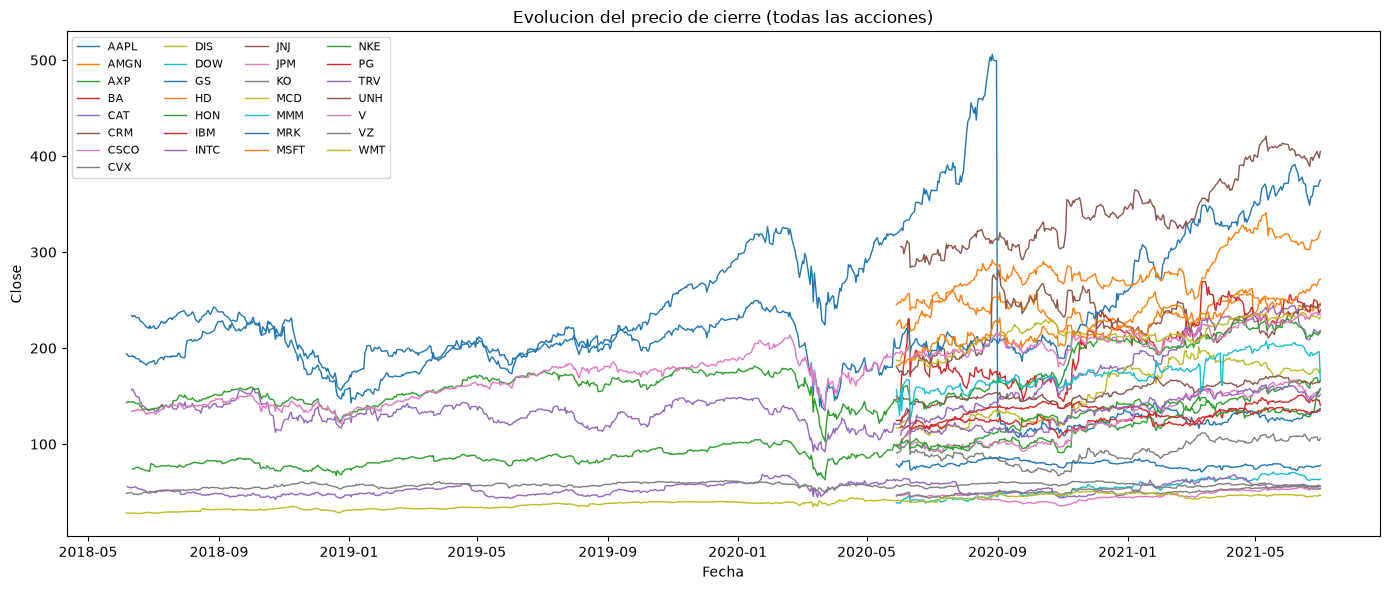

In [12]:
# Evolución del precio de cierre de todas las acciones
fig, ax = plt.subplots(figsize=(14, 6))
for symbol, g in df_daily.groupby("symbol"):
    ax.plot(g["date"], g["close"], label=symbol, linewidth=1)
ax.set_title("Evolucion del precio de cierre (todas las acciones)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Close")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

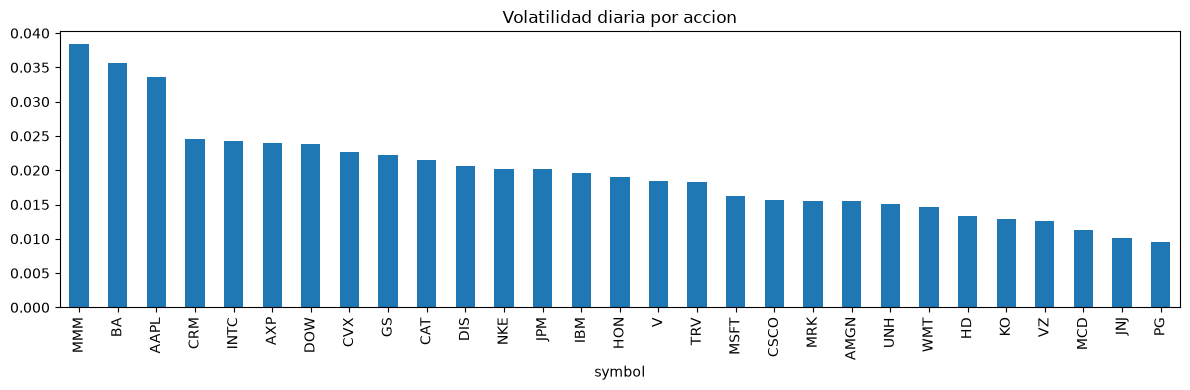

In [13]:
# Volatilidad (desviacion tipica de los retornos diarios) por accion,
# util mas adelante para justificar la seleccion de la cartera (Seccion 3)
retornos = df_daily.pivot(index="date", columns="symbol", values="close").pct_change()
volatilidad = retornos.std().sort_values(ascending=False)
volatilidad.plot(kind="bar", figsize=(12, 4), title="Volatilidad diaria por accion")
plt.tight_layout()
plt.show()

## 9. Guardado del dataset limpio

Guardamos el resultado para que el resto de scripts del proyecto (selección de
cartera, generación de datos sintéticos...) partan de aquí, sin repetir la
limpieza. La carpeta de datos no se sube al repositorio (indicado en las
instrucciones de entrega), así que el csv se guarda localmente.

In [ ]:
RUTA_SALIDA = os.path.join("Datos", "dowjones_limpio.csv")
df_daily.to_csv(RUTA_SALIDA, index=False)
print("Guardado en:", RUTA_SALIDA)